In [2]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style and default size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Uber trip dataset
trips = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Uber Trip Details.csv"
)

# Load the location lookup dataset
locations = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Location Table.csv"
)

# Create copies for analysis without changing the imported datasets
trips_analysis = trips.copy()
locations_analysis = locations.copy()

# Correct the dot separator in time values
# Example: 01-06-2024 0.42 becomes 01-06-2024 0:42
for column in ["Pickup Time", "Drop Off Time"]:
    trips_analysis[column] = (
        trips_analysis[column]
        .astype("string")
        .str.strip()
        .str.replace(
            r"(\d{1,2})\.(\d{2})$",
            r"\1:\2",
            regex=True
        )
    )

# Convert timestamps using the day-month-year format
for column in ["Pickup Time", "Drop Off Time"]:
    trips_analysis[column] = pd.to_datetime(
        trips_analysis[column],
        format="%d-%m-%Y %H:%M",
        errors="coerce"
    )

# Convert analysis columns to numeric values
for column in [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "Surge Fee"
]:
    trips_analysis[column] = pd.to_numeric(
        trips_analysis[column],
        errors="coerce"
    )

# Verify that the timestamps were converted successfully
print("Dataset shape:", trips_analysis.shape)
print(
    "Valid pickup timestamps:",
    trips_analysis["Pickup Time"].notna().sum()
)
print(
    "Valid drop-off timestamps:",
    trips_analysis["Drop Off Time"].notna().sum()
)

# Display sample records for verification
display(
    trips_analysis[
        ["Trip ID", "Pickup Time", "Drop Off Time",
         "trip_distance", "fare_amount"]
    ].head()
)

Dataset shape: (103728, 11)
Valid pickup timestamps: 103728
Valid drop-off timestamps: 103728


,Trip ID,Pickup Time,Drop Off Time,trip_distance,fare_amount
0,1,2024-06-01 00:42:00,2024-06-01 01:04:00,5.60,19.5
1,2,2024-06-01 00:06:00,2024-06-01 00:13:00,1.72,8.0
2,3,2024-06-01 00:08:00,2024-06-01 00:21:00,3.41,13.0
3,4,2024-06-01 00:28:00,2024-06-01 00:37:00,1.81,9.0
4,5,2024-06-01 00:38:00,2024-06-01 00:45:00,1.89,8.0


## Question 1 — What is the average trip duration by vehicle?

**Objective:**

Calculate the average duration of Uber trips for each vehicle type.

**Why are we running this?**

To understand how long trips typically take for different vehicle types and compare their trip-duration patterns.

,Vehicle,Average Trip Duration (Minutes)
0,UberX,16.143790
1,UberXL,15.942388
2,Uber Black,15.737163
3,Uber Comfort,15.721747
4,Uber Green,15.329563


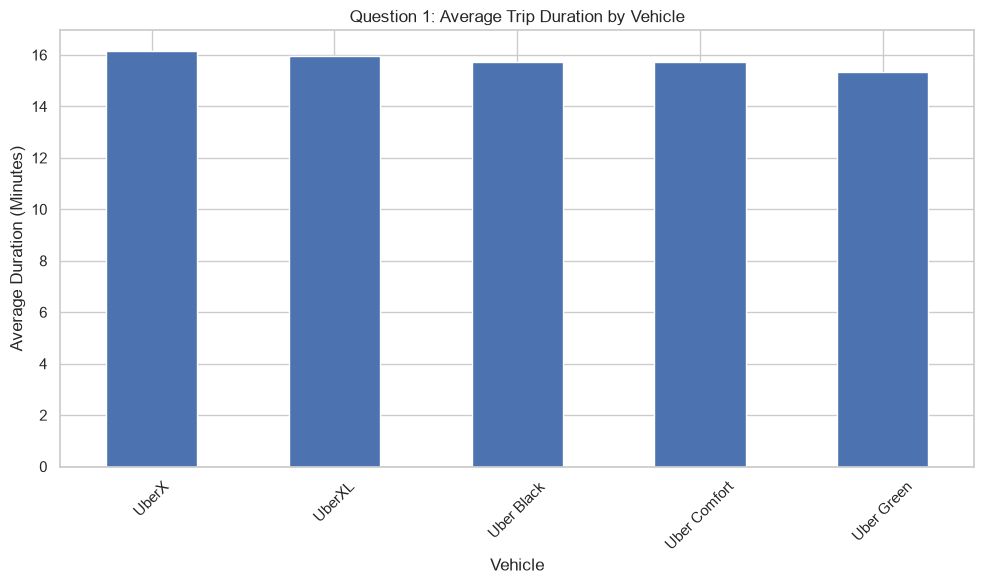

In [5]:
# Calculate trip duration in minutes
trips_analysis["Trip Duration Minutes"] = (
    trips_analysis["Drop Off Time"] - trips_analysis["Pickup Time"]
).dt.total_seconds() / 60

# Keep valid, non-negative durations and known vehicle types
valid_duration = trips_analysis[
    trips_analysis["Trip Duration Minutes"].notna()
    & (trips_analysis["Trip Duration Minutes"] >= 0)
    & trips_analysis["Vehicle"].notna()
].copy()

# Calculate average trip duration by vehicle
duration_by_vehicle = (
    valid_duration.groupby("Vehicle")["Trip Duration Minutes"]
    .mean()
    .sort_values(ascending=False)
)

# Display the average duration table
display(duration_by_vehicle.reset_index(
    name="Average Trip Duration (Minutes)"
))

# Plot average duration by vehicle
if not duration_by_vehicle.empty:
    duration_by_vehicle.plot(kind="bar")
    plt.title("Question 1: Average Trip Duration by Vehicle")
    plt.xlabel("Vehicle")
    plt.ylabel("Average Duration (Minutes)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid trip durations found. Check timestamp parsing.")

## Question 2 — What is the average trip speed by vehicle?

**Objective:**

Calculate the average distance travelled per hour for each vehicle type.

**Why are we running this?**

To compare trip speed patterns across vehicle types. The speed unit depends on the unit used in the `trip_distance` column.

,Vehicle,Average Trip Speed
0,Uber Green,15.320157
1,Uber Black,15.141858
2,UberX,15.124305
3,Uber Comfort,15.029175
4,UberXL,14.995230


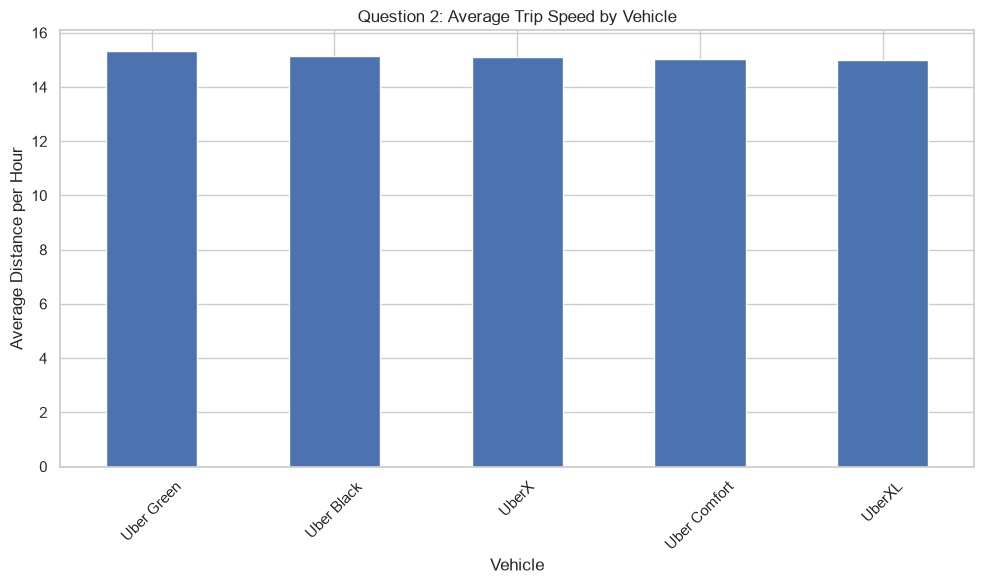

In [6]:
# Convert trip duration from minutes to hours
valid_duration["Trip Duration Hours"] = (
    valid_duration["Trip Duration Minutes"] / 60
)

# Keep trips with positive duration and valid distance
valid_speed = valid_duration[
    valid_duration["Trip Duration Hours"].gt(0)
    & valid_duration["trip_distance"].notna()
    & valid_duration["trip_distance"].ge(0)
].copy()

# Calculate distance travelled per hour for each trip
valid_speed["Average Trip Speed"] = (
    valid_speed["trip_distance"] / valid_speed["Trip Duration Hours"]
)

# Calculate average speed by vehicle
speed_by_vehicle = (
    valid_speed.groupby("Vehicle")["Average Trip Speed"]
    .mean()
    .sort_values(ascending=False)
)

# Display average speed by vehicle
display(speed_by_vehicle.reset_index(name="Average Trip Speed"))

# Plot average speed by vehicle
if not speed_by_vehicle.empty:
    speed_by_vehicle.plot(kind="bar")
    plt.title("Question 2: Average Trip Speed by Vehicle")
    plt.xlabel("Vehicle")
    plt.ylabel("Average Distance per Hour")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid trip speed values found.")

## Question 3 — Which pickup hours generate the most fare revenue?

**Objective:**

Calculate the total fare revenue generated during each hour of the day.

**Why are we running this?**

To identify the hours that contribute the most fare revenue and understand when revenue activity is highest.

,Pickup Hour,Total Fare Revenue
0,0,22025.00
1,1,13718.00
2,2,7684.23
3,3,5755.50
4,4,5321.62
5,5,11864.00
6,6,30775.00
7,7,47429.70
8,8,56963.00
9,9,67202.50


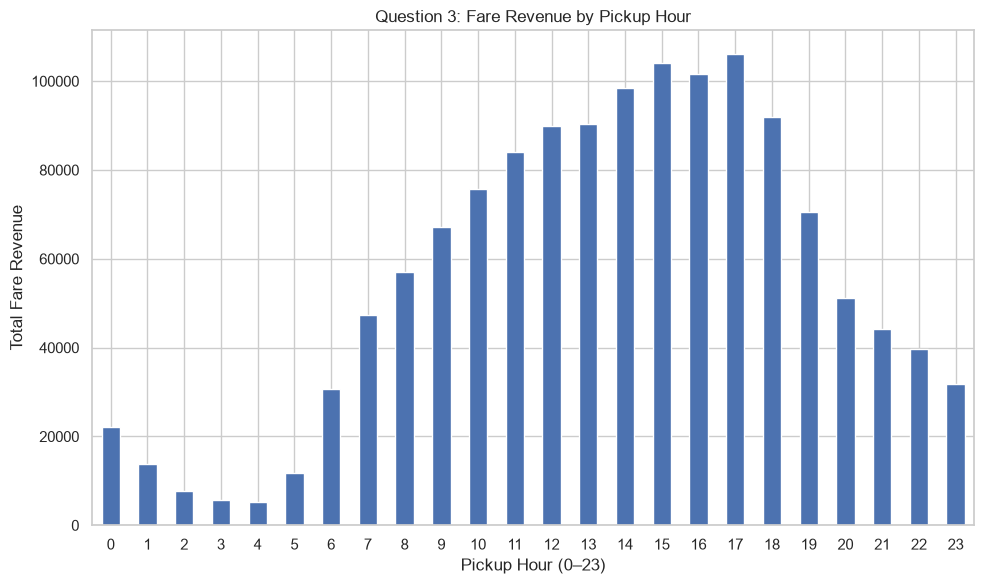

In [7]:
# Keep trips with valid pickup timestamps and fare amounts
valid_revenue = trips_analysis.dropna(
    subset=["Pickup Time", "fare_amount"]
).copy()

# Extract the pickup hour
valid_revenue["Pickup Hour"] = valid_revenue["Pickup Time"].dt.hour

# Calculate total fare revenue by pickup hour
revenue_by_hour = (
    valid_revenue.groupby("Pickup Hour")["fare_amount"]
    .sum()
    .sort_index()
)

# Display the hourly revenue table
display(revenue_by_hour.reset_index(name="Total Fare Revenue"))

# Plot hourly fare revenue
if not revenue_by_hour.empty:
    revenue_by_hour.plot(kind="bar")
    plt.title("Question 3: Fare Revenue by Pickup Hour")
    plt.xlabel("Pickup Hour (0–23)")
    plt.ylabel("Total Fare Revenue")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No valid hourly revenue data found.")

## Question 4 — Fare Revenue by Weekday

**Objective:**

Calculate the total fare revenue generated on each day of the week, from Monday to Sunday.

**Why are we running this?**

This analysis helps identify which weekdays generate the most fare revenue and supports business decisions about driver availability and demand planning.

,Weekday,Total Fare Revenue
0,Monday,0.0
1,Tuesday,0.0
2,Wednesday,0.0
3,Thursday,0.0
4,Friday,0.0
5,Saturday,0.0
6,Sunday,0.0


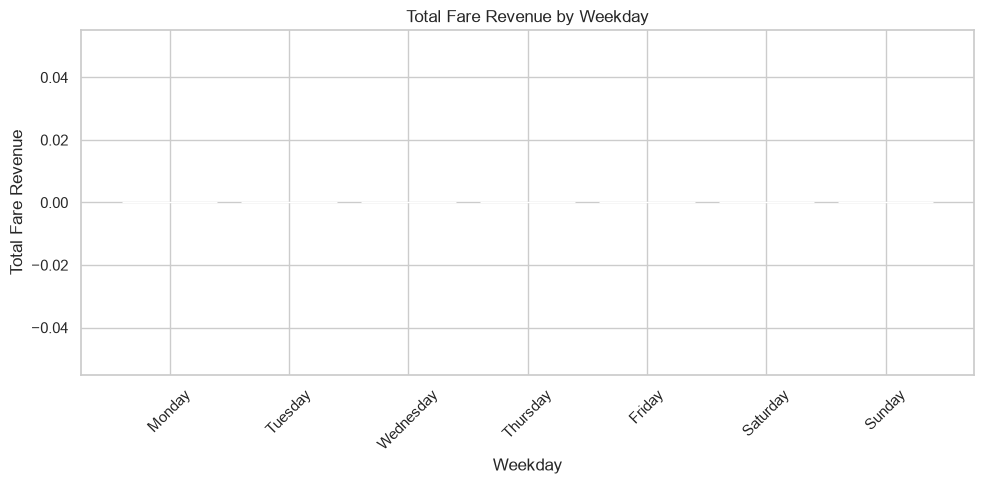

In [12]:
# Import pandas for data manipulation
import pandas as pd

# Create a copy of the analysis dataset
weekday_analysis = trips_analysis.copy()

# Convert Pickup Time to datetime using the dataset's date format
weekday_analysis["Pickup Time"] = (
    weekday_analysis["Pickup Time"]
    .astype("string")
    .str.strip()
    .str.replace(r"(\d{1,2})\.(\d{2})$", r"\1:\2", regex=True)
)

weekday_analysis["Pickup Time"] = pd.to_datetime(
    weekday_analysis["Pickup Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Keep rows with valid pickup times and fare amounts
weekday_analysis = weekday_analysis.dropna(
    subset=["Pickup Time", "fare_amount"]
).copy()

# Extract weekday number: Monday = 0, Sunday = 6
weekday_analysis["Weekday Number"] = (
    weekday_analysis["Pickup Time"].dt.dayofweek
)

# Map weekday numbers to weekday names
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_analysis["Weekday"] = (
    weekday_analysis["Weekday Number"].map(weekday_names)
)

# Calculate total fare revenue for each weekday
revenue_by_weekday = (
    weekday_analysis.groupby("Weekday Number")["fare_amount"]
    .sum()
    .reindex(range(7), fill_value=0)
)

# Rename weekday index values
revenue_by_weekday.index = [
    weekday_names[day] for day in revenue_by_weekday.index
]

# Convert the result into a DataFrame
weekday_table = revenue_by_weekday.rename(
    "Total Fare Revenue"
).reset_index()

# Rename columns to avoid the pandas reset_index(names=...) error
weekday_table.columns = ["Weekday", "Total Fare Revenue"]

# Display the revenue table
display(weekday_table)

# Plot total fare revenue by weekday
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    weekday_table["Weekday"],
    weekday_table["Total Fare Revenue"]
)

plt.title("Total Fare Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Fare Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Question 5 — Which routes have the highest average fare?

**Objective:**

Identify pickup-to-drop-off routes with the highest average fare.

**Why are we running this?**

To understand which routes are associated with higher fares. Only routes with at least five unique trips are included to reduce the effect of very small samples.


In [13]:
# Create a lookup table for location names
location_lookup = locations_analysis[
    ["LocationID", "Location"]
].drop_duplicates(subset=["LocationID"])

# Prepare the pickup location lookup
pickup_lookup = location_lookup.rename(columns={
    "LocationID": "PULocationID",
    "Location": "Pickup Location"
})

# Prepare the drop-off location lookup
dropoff_lookup = location_lookup.rename(columns={
    "LocationID": "DOLocationID",
    "Location": "Drop-off Location"
})

# Join pickup location names to the trip data
routes = trips_analysis.merge(
    pickup_lookup, on="PULocationID", how="left"
)

# Join drop-off location names to the trip data
routes = routes.merge(
    dropoff_lookup, on="DOLocationID", how="left"
)

# Keep records with valid routes, trip IDs, and fares
routes_valid = routes.dropna(subset=[
    "Pickup Location", "Drop-off Location", "Trip ID", "fare_amount"
])

# Calculate trip count and average fare for each route
route_fares = (
    routes_valid.groupby(["Pickup Location", "Drop-off Location"])
    .agg(
        Total_Trips=("Trip ID", "nunique"),
        Average_Fare=("fare_amount", "mean")
    )
    .query("Total_Trips >= 5")
    .sort_values("Average_Fare", ascending=False)
    .head(10)
)

# Display the ten highest-average-fare routes
display(route_fares.reset_index())

,Pickup Location,Drop-off Location,Total_Trips,Average_Fare
0,Hammels/Arverne,Upper East Side South,5,70.000000
1,JFK Airport,Riverdale/North Riverdale/Fieldston,7,69.214286
2,JFK Airport,Spuyten Duyvil/Kingsbridge,5,67.400000
3,JFK Airport,Sunset Park West,6,66.000000
4,JFK Airport,Windsor Terrace,5,61.400000
5,JFK Airport,Williamsbridge/Olinville,5,61.100000
6,JFK Airport,Borough Park,7,57.928571
7,JFK Airport,Kensington,6,57.583333
8,JFK Airport,Bensonhurst West,8,56.812500
9,JFK Airport,Carroll Gardens,12,56.666667


## Question 6 — Which vehicle types generate the highest average fare per trip?

**Objective:**

Compare total fare revenue and average fare per trip across vehicle types.

**Why are we running this?**

Total revenue depends partly on the number of trips. Average fare per trip provides another way to compare vehicle categories.

,Vehicle,Total_Trips,Total_Fare_Revenue,Average_Fare_Per_Trip
0,UberX,38744,507140.77,13.089531
1,Uber Black,16710,217094.00,12.991861
2,UberXL,16698,216026.50,12.937268
3,Uber Green,14498,187445.20,12.929038
4,Uber Comfort,17078,220584.98,12.916324


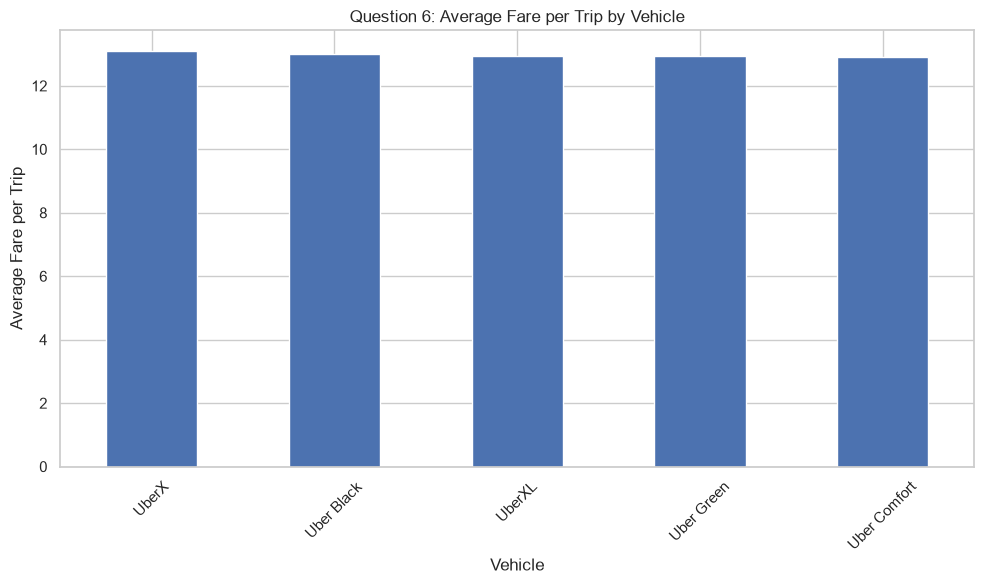

In [14]:
# Keep records with vehicle type, trip ID, and valid fare amounts
vehicle_fares = trips_analysis.dropna(
    subset=["Vehicle", "Trip ID", "fare_amount"]
).copy()

# Calculate trip count, total fare revenue, and average fare by vehicle
vehicle_revenue_summary = (
    vehicle_fares.groupby("Vehicle")
    .agg(
        Total_Trips=("Trip ID", "nunique"),
        Total_Fare_Revenue=("fare_amount", "sum"),
        Average_Fare_Per_Trip=("fare_amount", "mean")
    )
    .sort_values("Average_Fare_Per_Trip", ascending=False)
)

# Display the vehicle revenue summary
display(vehicle_revenue_summary.reset_index())

# Plot average fare per trip by vehicle
if not vehicle_revenue_summary.empty:
    vehicle_revenue_summary["Average_Fare_Per_Trip"].plot(kind="bar")
    plt.title("Question 6: Average Fare per Trip by Vehicle")
    plt.xlabel("Vehicle")
    plt.ylabel("Average Fare per Trip")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Question 7 — How strongly are trip distance and fare amount related?

**Objective:**

Explore the relationship between trip distance and fare amount.

**Why are we running this?**

To see whether longer trips tend to have higher fares and measure the strength of their linear relationship using correlation.

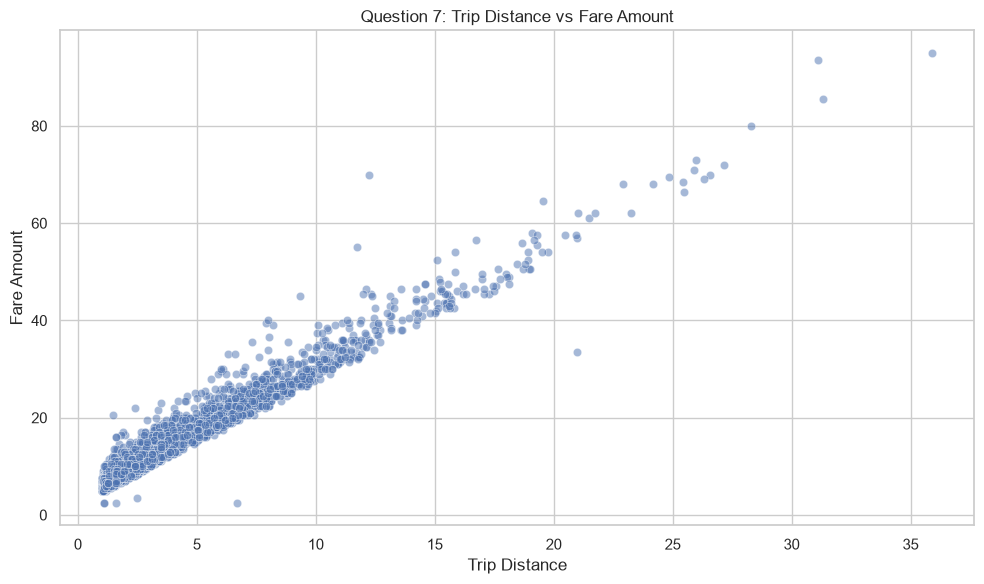

Distance-fare correlation: 0.975


In [15]:
# Keep trips with valid non-negative distance and fare values
distance_fare = trips_analysis[
    trips_analysis["trip_distance"].notna()
    & trips_analysis["fare_amount"].notna()
    & trips_analysis["trip_distance"].ge(0)
    & trips_analysis["fare_amount"].ge(0)
].copy()

# Sample up to 5,000 trips to keep the scatter plot readable
if not distance_fare.empty:
    plot_sample = distance_fare.sample(
        n=min(5000, len(distance_fare)),
        random_state=42
    )

    # Plot trip distance against fare amount
    sns.scatterplot(
        data=plot_sample,
        x="trip_distance",
        y="fare_amount",
        alpha=0.5
    )
    plt.title("Question 7: Trip Distance vs Fare Amount")
    plt.xlabel("Trip Distance")
    plt.ylabel("Fare Amount")
    plt.tight_layout()
    plt.show()
else:
    print("No valid distance and fare values found.")

# Calculate correlation when enough records exist
if len(distance_fare) > 1:
    correlation = distance_fare["trip_distance"].corr(
        distance_fare["fare_amount"]
    )
    print("Distance-fare correlation:", round(correlation, 3))

## Question 8 — Which pickup locations have the highest average fare?

**Objective:**

Find the pickup locations associated with the highest average fare.

**Why are we running this?**

To compare average fares across pickup areas. Only locations with at least five unique trips are included so that locations with very few trips do not dominate the results.

,Pickup Location,Total_Trips,Average_Fare
0,Charleston/Tottenville,8,93.000000
1,Cambria Heights,13,61.500000
2,Hammels/Arverne,15,60.166667
3,Far Rockaway,7,56.642857
4,Coney Island,5,54.000000
5,Madison,7,52.428571
6,Grymes Hill/Clifton,6,49.083333
7,Queens Village,9,48.222222
8,Marine Park/Mill Basin,6,45.750000
9,West Farms/Bronx River,10,45.500000


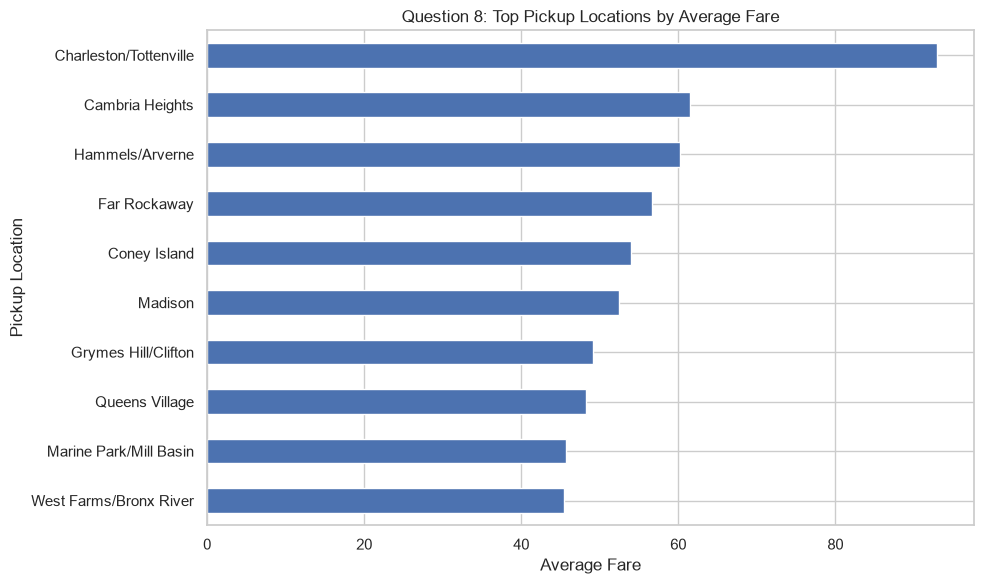

In [16]:
# Join pickup location names to trip records
pickup_fares = trips_analysis.merge(
    pickup_lookup, on="PULocationID", how="left"
)

# Keep rows with known pickup locations and valid fares
pickup_fares = pickup_fares.dropna(
    subset=["Pickup Location", "fare_amount", "Trip ID"]
)

# Calculate trip count and average fare for each pickup location
pickup_fare_summary = (
    pickup_fares.groupby("Pickup Location")
    .agg(
        Total_Trips=("Trip ID", "nunique"),
        Average_Fare=("fare_amount", "mean")
    )
    .query("Total_Trips >= 5")
    .sort_values("Average_Fare", ascending=False)
    .head(10)
)

# Display the top pickup locations by average fare
display(pickup_fare_summary.reset_index())

# Plot the top pickup locations when results are available
if not pickup_fare_summary.empty:
    pickup_fare_summary["Average_Fare"].sort_values().plot(kind="barh")
    plt.title("Question 8: Top Pickup Locations by Average Fare")
    plt.xlabel("Average Fare")
    plt.ylabel("Pickup Location")
    plt.tight_layout()
    plt.show()
else:
    print("No pickup locations met the minimum trip-count requirement.")

## Question 9 — What percentage of trips include a surge fee?

**Objective:**

Calculate the percentage of unique trips with a positive surge fee.

**Why are we running this?**

To understand how common surge fees are in the dataset. This analysis assumes a value greater than zero in `Surge Fee` means the trip included a surge fee.

In [17]:
# Keep records with valid trip IDs and surge fee values
surge_data = trips_analysis.dropna(
    subset=["Surge Fee", "Trip ID"]
).copy()

# Flag trips with a positive surge fee
surge_data["Has Surge Fee"] = surge_data["Surge Fee"] > 0

# Count unique trips with and without a surge fee
surge_summary = (
    surge_data.groupby("Has Surge Fee")["Trip ID"]
    .nunique()
    .rename(index={
        False: "No Surge Fee",
        True: "Surge Fee"
    })
    .rename("Total Trips")
    .reset_index()
)

# Calculate the total number of unique trips
total_trips = surge_data["Trip ID"].nunique()

# Calculate unique trips with a positive surge fee
trips_with_surge = surge_data.loc[
    surge_data["Has Surge Fee"], "Trip ID"
].nunique()

# Calculate the percentage of trips with a surge fee
surge_percentage = (
    trips_with_surge / total_trips * 100
    if total_trips > 0 else np.nan
)

# Display surge counts and percentage
display(surge_summary)
print(f"Trips with a surge fee: {surge_percentage:.2f}%")

,Has Surge Fee,Total Trips
0,No Surge Fee,37802
1,Surge Fee,65926


Trips with a surge fee: 63.56%


## Question 10 — How do monthly trip demand and fare revenue compare?

**Objective:**

Calculate monthly trip counts, total fare revenue, and average fare in one summary.

**Why are we running this?**

To compare trip demand with fare revenue over time and identify months with higher or lower business activity. This analysis uses the corrected pickup timestamps from the setup cell.

,Revenue Month,Total_Trips,Total_Fare_Revenue,Average_Fare
0,2024-06,103728,1348291.45,12.998337


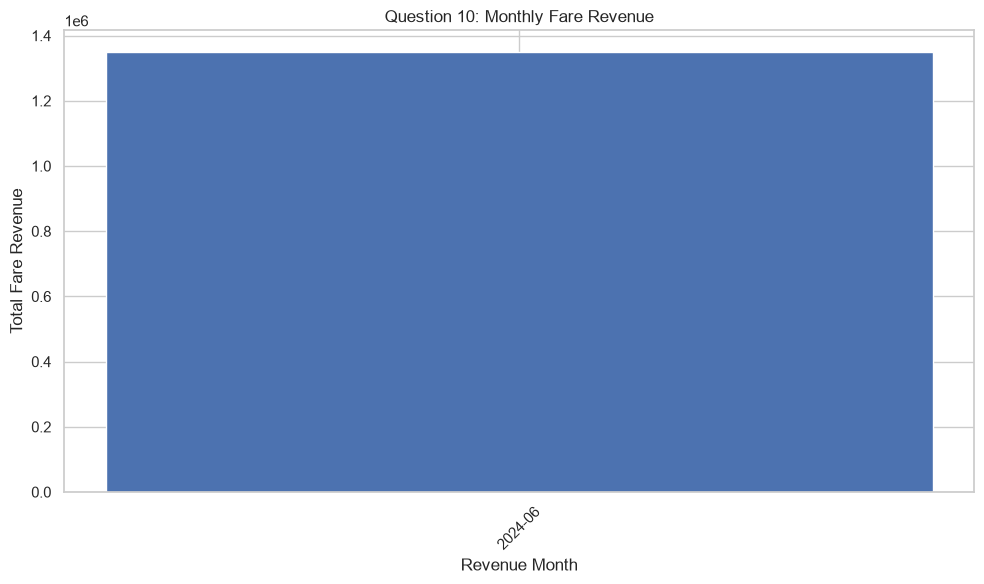

In [18]:
# Keep trips with valid pickup timestamps, trip IDs, and fare amounts
monthly_data = trips_analysis.dropna(
    subset=["Pickup Time", "Trip ID", "fare_amount"]
).copy()

# Extract the year and month from each pickup timestamp
monthly_data["Revenue Month"] = (
    monthly_data["Pickup Time"].dt.to_period("M")
)

# Calculate monthly trip count, fare revenue, and average fare
monthly_summary = (
    monthly_data.groupby("Revenue Month")
    .agg(
        Total_Trips=("Trip ID", "nunique"),
        Total_Fare_Revenue=("fare_amount", "sum"),
        Average_Fare=("fare_amount", "mean")
    )
    .sort_index()
)

# Display the monthly business summary
display(monthly_summary.reset_index())

# Plot monthly fare revenue without a single-month axis warning
if not monthly_summary.empty:
    month_labels = monthly_summary.index.astype(str)

    plt.figure(figsize=(10, 6))
    plt.bar(month_labels, monthly_summary["Total_Fare_Revenue"])

    # Add chart title and axis labels
    plt.title("Question 10: Monthly Fare Revenue")
    plt.xlabel("Revenue Month")
    plt.ylabel("Total Fare Revenue")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid monthly data found. Check the timestamp parsing counts.")